# Taller · De los datos a un dashboard publicado

**Programación — ADMI 1301**

Trabajarás con las **2.000 ventas de una cadena de papelerías en 2025**. En este taller vas a:

1. **Graficar** (6 ejercicios con `groupby`, `crosstab` y `pivot_table`).
2. **Organizar** tus gráficos en una sola figura con `subplots`: tu *dashboard*.
3. **Embellecerlo con prompts**: le pides a Gemini que reescriba el código de tu figura y pegas su respuesta aquí.
4. **Elegir tu versión favorita**, escribir tus conclusiones y **publicar tu notebook en GitHub**.

Las instrucciones completas están en la guía en Word. Aquí encuentras lo esencial de cada ejercicio y una **verificación** (`assert`) para saber si vas bien.

**Escriba los nombres de los integrantes aca.**
______________________________________________________________________  
 1.   Alejandra Giraldo
 2.   
 3.    
    


## 0. Preparación
Ejecuta la celda y sube el archivo **`ventas_papelerias_2025.csv`**.

In [32]:
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files
from IPython.display import display

subidos = files.upload()   # selecciona ventas_papelerias_2025.csv

df = pd.read_csv("ventas_papelerias_2025.csv")
df["fecha"] = pd.to_datetime(df["fecha"])
df["mes"] = df["fecha"].dt.month        # 1 = enero ... 12 = diciembre
df.head()

Saving ventas_papelerias_2025.csv to ventas_papelerias_2025 (2).csv


,id_venta,fecha,ciudad,canal,segmento,vendedor,producto,categoria,metodo_pago,cantidad,precio_unitario,descuento,total,mes
0,V0001,2025-01-01,Cali,Tienda,Corporativo,Julián Cortés,Resma carta,Papel,Transferencia,6,18000,0.10,97200,1
1,V0002,2025-01-01,Medellín,Telefónico,Corporativo,Andrés Rojas,Carpeta,Organización,Transferencia,21,2500,0.00,52500,1
2,V0003,2025-01-01,Barranquilla,Telefónico,Mayorista,Mateo Peña,Cuaderno,Papel,Transferencia,65,3500,0.10,204750,1
3,V0004,2025-01-02,Bucaramanga,Online,Minorista,Isabela Mora,Colores x12,Arte,Tarjeta,6,8500,0.00,51000,1
4,V0005,2025-01-02,Medellín,Telefónico,Mayorista,Andrés Rojas,Esfero,Escritura,Tarjeta,67,1200,0.15,68340,1


**Conoce tus datos** antes de graficar: cuántas filas hay, qué columnas, qué valores tiene cada categoría.

In [33]:
print(df.shape)
df.info()
for col in ["ciudad", "canal", "segmento", "categoria", "metodo_pago"]:
    print(col, "->", sorted(df[col].unique()))

(2000, 14)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   id_venta         2000 non-null   object        
 1   fecha            2000 non-null   datetime64[ns]
 2   ciudad           2000 non-null   object        
 3   canal            2000 non-null   object        
 4   segmento         2000 non-null   object        
 5   vendedor         2000 non-null   object        
 6   producto         2000 non-null   object        
 7   categoria        2000 non-null   object        
 8   metodo_pago      2000 non-null   object        
 9   cantidad         2000 non-null   int64         
 10  precio_unitario  2000 non-null   int64         
 11  descuento        2000 non-null   float64       
 12  total            2000 non-null   int64         
 13  mes              2000 non-null   int32         
dtypes: datetime64[ns](1), float64

---
# Parte A · Seis gráficos
En cada ejercicio: **(1)** prepara una tabla con `groupby`, `crosstab` o `pivot_table`, **(2)** guárdala en la variable indicada, **(3)** grafícala. Ponle **título** a cada gráfico.

### Ejercicio 1 · Top 5 de productos *(barras horizontales)*
**Contexto.** La gerente de compras debe decidir en qué productos concentrar el inventario del próximo año.

**Tarea.** Calcula los ingresos (`total`) por `producto`, quédate con los **5 mayores** y grafícalos en barras horizontales. Guarda la tabla en **`top_productos`**.

*Herramientas:* `groupby`, `sum`, `sort_values`, `head`, `.plot.barh()`

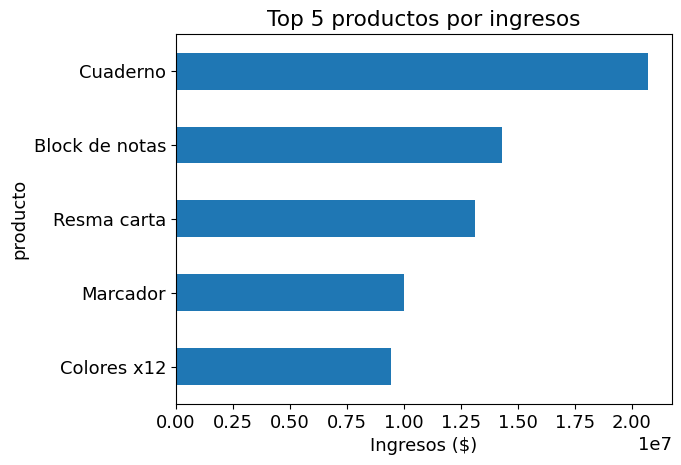

In [34]:
# Ejercicio 1
top_productos = (df.groupby("producto")["total"].sum()
                   .sort_values(ascending=False).head(5))
top_productos.sort_values().plot.barh(title="Top 5 productos por ingresos")
plt.xlabel("Ingresos ($)")
plt.show()

In [35]:
# ✅ Verificación
assert len(top_productos) == 5, "Debe haber exactamente 5 productos"
assert top_productos.index[0] == "Cuaderno", "El producto con más ingresos no coincide: revisa el ordenamiento"
assert abs(top_productos.iloc[0] - 20712345) < 1, "Revisa que estés sumando la columna total"
print("Ejercicio 1 correcto ✔")

Ejercicio 1 correcto ✔


### Ejercicio 2 · Ingresos mes a mes: Bogotá vs Medellín *(líneas)*
**Contexto.** La dirección regional quiere comparar la evolución de sus dos ciudades principales durante el año.

**Tarea.** **Selecciona** solo las ventas de Bogotá y Medellín (`isin`). Con una **tabla dinámica** pon los meses en las filas, las ciudades en las columnas y la suma de `total` como valores. Guárdala en **`ing_mes_ciudad`** y grafícala como líneas con marcadores.

*Herramientas:* filtrado con `isin`, `pivot_table`, `.plot.line(marker="o")`

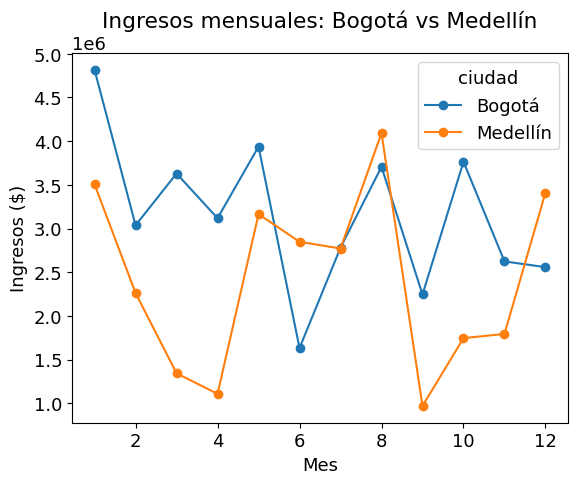

In [36]:
# Ejercicio 2
bm = df[df["ciudad"].isin(["Bogotá", "Medellín"])]
ing_mes_ciudad = bm.pivot_table(index="mes", columns="ciudad",
                                values="total", aggfunc="sum")
ing_mes_ciudad.plot.line(marker="o", title="Ingresos mensuales: Bogotá vs Medellín")
plt.xlabel("Mes"); plt.ylabel("Ingresos ($)")
plt.show()

In [37]:
# ✅ Verificación
assert ing_mes_ciudad.shape == (12, 2), f"Se esperaba una tabla de 12 meses x 2 ciudades, tienes {ing_mes_ciudad.shape}"
assert set(ing_mes_ciudad.columns) == {"Bogotá", "Medellín"}, "Las columnas deben ser las dos ciudades"
assert abs(ing_mes_ciudad["Bogotá"].sum() - 37847614) < 1, "El total de Bogotá no coincide"
print("Ejercicio 2 correcto ✔")

Ejercicio 2 correcto ✔


### Ejercicio 3 · ¿Por qué canal se vende más? *(gráfico de pie)*
**Contexto.** La empresa evalúa si invierte más en su tienda online o en la atención telefónica.

**Tarea.** Calcula los ingresos totales por `canal`, guárdalos en **`ing_canal`** y grafica la participación de cada canal con un gráfico de pie que muestre los **porcentajes con un decimal**.

*Herramientas:* `groupby`, `.plot.pie(autopct=...)`

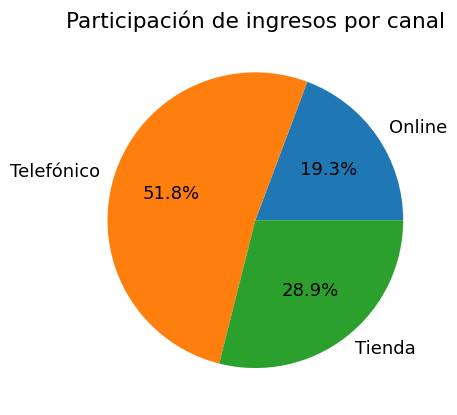

In [38]:
# Ejercicio 3
ing_canal = df.groupby("canal")["total"].sum()
ing_canal.plot.pie(autopct="%1.1f%%", title="Participación de ingresos por canal")
plt.ylabel("")
plt.show()

In [39]:
# ✅ Verificación
assert abs(ing_canal.sum() - 118668012) < 1, "La suma de los canales debe ser el ingreso total"
assert abs(ing_canal["Telefónico"] / ing_canal.sum() - 0.520) < 0.01, "La participación del canal Telefónico no coincide"
print("Ejercicio 3 correcto ✔")

Ejercicio 3 correcto ✔


### Ejercicio 4 · ¿Cada segmento compra lo mismo? *(barras apiladas)*
**Contexto.** El área comercial sospecha que los clientes corporativos compran productos distintos a los minoristas.

**Tarea.** Con `pd.crosstab` cuenta las ventas por `segmento` (filas) y `categoria` (columnas), **normalizadas por fila** y expresadas en **porcentaje** (de 0 a 100). Guarda la tabla en **`tabla_seg_cat`** y grafícala en barras **apiladas**.

*Herramientas:* `pd.crosstab(..., normalize="index")`, `.plot.bar(stacked=True)`

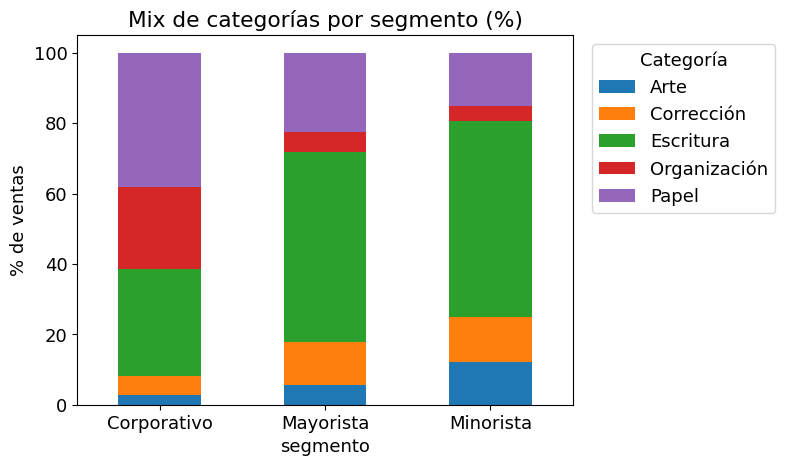

In [40]:
# Ejercicio 4
tabla_seg_cat = pd.crosstab(df["segmento"], df["categoria"], normalize="index") * 100
tabla_seg_cat.plot.bar(stacked=True, title="Mix de categorías por segmento (%)")
plt.ylabel("% de ventas"); plt.xticks(rotation=0)
plt.legend(title="Categoría", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

In [41]:
# ✅ Verificación
assert tabla_seg_cat.shape == (3, 5), f"Se esperaba 3 segmentos x 5 categorías, tienes {tabla_seg_cat.shape}"
assert (abs(tabla_seg_cat.sum(axis=1) - 100) < 0.01).all(), "Cada fila debe sumar 100 (usa normalize y multiplica por 100)"
print("Ejercicio 4 correcto ✔")

Ejercicio 4 correcto ✔


### Ejercicio 5 · Productividad de los vendedores *(dispersión)*
**Contexto.** Recursos humanos revisa qué vendedores concretan más ventas y cuáles venden tickets más altos.

**Tarea.** Con `groupby` por `vendedor` y `ciudad`, calcula para cada vendedor el **número de ventas** (`n_ventas`) y el **valor promedio de sus ventas** (`ticket_prom`). Guarda la tabla en **`vend`** (con índice normal: usa `reset_index()`). Haz una dispersión (`n_ventas` en X, `ticket_prom` en Y) con un **color por ciudad** y leyenda.

*Herramientas:* `groupby().agg(nombre=("columna", "función"))`, `reset_index`, `plt.scatter` dentro de un `for`

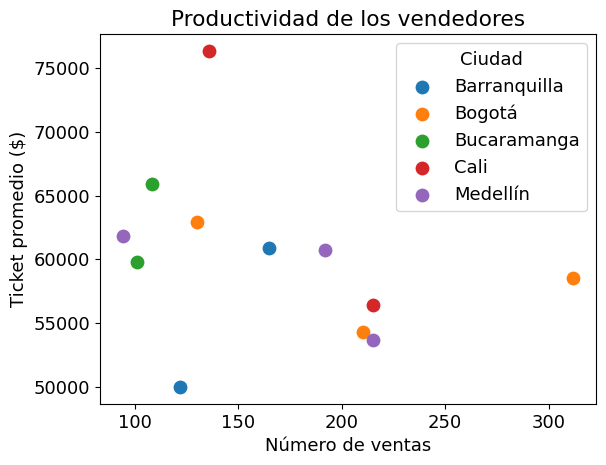

In [42]:
# Ejercicio 5
vend = (df.groupby(["vendedor", "ciudad"])
          .agg(n_ventas=("id_venta", "count"), ticket_prom=("total", "mean"))
          .reset_index())
for ciudad, g in vend.groupby("ciudad"):
    plt.scatter(g["n_ventas"], g["ticket_prom"], label=ciudad, s=80)
plt.xlabel("Número de ventas"); plt.ylabel("Ticket promedio ($)")
plt.title("Productividad de los vendedores"); plt.legend(title="Ciudad")
plt.show()

In [43]:
# ✅ Verificación
assert vend.shape[0] == 12, f"Debe haber una fila por vendedor (12), tienes {vend.shape[0]}"
assert {"vendedor", "ciudad", "n_ventas", "ticket_prom"} <= set(vend.columns), "Faltan columnas: vendedor, ciudad, n_ventas, ticket_prom"
assert vend["n_ventas"].sum() == 2000, "La suma de n_ventas debe ser 2000"
print("Ejercicio 5 correcto ✔")

Ejercicio 5 correcto ✔


### Ejercicio 6 · ¿Qué tan grandes son las ventas de cada segmento? *(diagrama de cajas)*
**Contexto.** Para planear el segundo semestre, finanzas quiere ver cómo se distribuye el valor de las ventas por tipo de cliente.

**Tarea.** **Selecciona** solo las ventas del **segundo semestre** (`mes` de 7 a 12) y guárdalas en **`sem2`**. Haz un diagrama de cajas del `total` por `segmento`, **sin mostrar los valores atípicos** (`showfliers=False`).

*Herramientas:* filtro con `>=`, `.boxplot(column=..., by=...)`

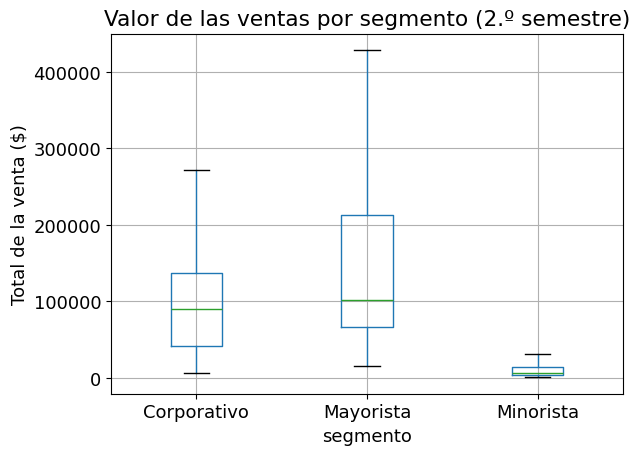

In [44]:
# Ejercicio 6
sem2 = df[df["mes"] >= 7]
sem2.boxplot(column="total", by="segmento", showfliers=False)
plt.suptitle("")   # quita el título automático de pandas
plt.title("Valor de las ventas por segmento (2.º semestre)")
plt.ylabel("Total de la venta ($)")
plt.show()

In [45]:
# ✅ Verificación
assert len(sem2) == 1050, f"El segundo semestre debe tener 1050 ventas, tienes {len(sem2)}"
print("Ejercicio 6 correcto ✔")

Ejercicio 6 correcto ✔


---
# Parte B · Todo en una sola figura (`subplots`)
### Ejercicio 7 · Organiza tus 6 gráficos en una cuadrícula de 2 × 3
**Contexto.** La gerente quiere ver todo en **una sola imagen** para presentarla en la junta.

**Tarea.** Crea una figura con `fig, axs = plt.subplots(2, 3, figsize=(18, 10))` y dibuja cada gráfico en su posición pasando **`ax=axs[fila, columna]`**. Agrega un título general con `fig.suptitle(...)` y termina con `plt.tight_layout()`.

**Importante:** escribe el código en la celda que empieza con `%%writefile figura_base.py` (así el programa guarda tu código en un archivo, que usarás en la Parte C). Luego ejecuta la celda siguiente (`%run -i figura_base.py`) para ver la figura.

*Pistas:* `plot.barh(ax=axs[0, 0])` · `plot.pie(...)` también acepta `ax` · para el boxplot: `boxplot(column=..., by=..., ax=...)` · para la dispersión: `axs[1, 1].scatter(...)`

In [46]:
%%writefile figura_base.py
import pandas as pd
import matplotlib.pyplot as plt

top_productos = df.groupby("producto")["total"].sum().sort_values(ascending=False).head(5)
bm = df[df["ciudad"].isin(["Bogotá", "Medellín"])]
ing_mes_ciudad = bm.pivot_table(index="mes", columns="ciudad", values="total", aggfunc="sum")
ing_canal = df.groupby("canal")["total"].sum()
tabla_seg_cat = pd.crosstab(df["segmento"], df["categoria"], normalize="index") * 100
vend = (df.groupby(["vendedor", "ciudad"])
          .agg(n_ventas=("id_venta", "count"), ticket_prom=("total", "mean"))
          .reset_index())
sem2 = df[df["mes"] >= 7]

fig, axs = plt.subplots(2, 3, figsize=(18, 10))

top_productos.sort_values().plot.barh(ax=axs[0, 0], title="Top 5 productos por ingresos")
axs[0, 0].set_xlabel("Ingresos ($)")

ing_mes_ciudad.plot.line(ax=axs[0, 1], marker="o", title="Ingresos mensuales: Bogotá vs Medellín")
axs[0, 1].set_xlabel("Mes"); axs[0, 1].set_ylabel("Ingresos ($)")

ing_canal.plot.pie(ax=axs[0, 2], autopct="%1.1f%%", title="Ingresos por canal")
axs[0, 2].set_ylabel("")

tabla_seg_cat.plot.bar(ax=axs[1, 0], stacked=True, title="Mix de categorías por segmento (%)")
axs[1, 0].set_xlabel(""); axs[1, 0].set_ylabel("% de ventas")
axs[1, 0].tick_params(axis="x", rotation=0)

for ciudad, g in vend.groupby("ciudad"):
    axs[1, 1].scatter(g["n_ventas"], g["ticket_prom"], label=ciudad, s=80)
axs[1, 1].set_title("Productividad de los vendedores")
axs[1, 1].set_xlabel("Número de ventas"); axs[1, 1].set_ylabel("Ticket promedio ($)")
axs[1, 1].legend(title="Ciudad")

sem2.boxplot(column="total", by="segmento", ax=axs[1, 2], showfliers=False)
axs[1, 2].set_title("Valor de las ventas por segmento (2.º semestre)")
axs[1, 2].set_xlabel(""); axs[1, 2].set_ylabel("Total ($)")

fig.suptitle("Ventas de la cadena de papelerías · 2025", fontsize=18)
plt.tight_layout()
# Ejercicio 7: código de la figura 2x3
# Empieza con:  fig, axs = plt.subplots(2, 3, figsize=(18, 10))

Overwriting figura_base.py


In [47]:
%run -i figura_base.py

In [48]:
# ✅ Verificación
assert len(fig.axes) >= 6, f"La figura debe tener 6 gráficos, tiene {len(fig.axes)}"
print("Ejercicio 7 correcto ✔")

Ejercicio 7 correcto ✔


---
# Parte C · Hazla ver bonita con prompts
Ahora **tú escribes el prompt** y se lo envías a Gemini (en [gemini.google.com](https://gemini.google.com) o la IA que prefieras). Gemini **reescribe el código** de tu figura para que se vea profesional, casi como un dashboard. Tú pegas ese código en el notebook y lo ejecutas.

**El ciclo, cada vez:**
1. Ejecuta la celda de herramientas: te muestra **tu código actual** y las **reglas técnicas**.
2. Escribe tu prompt (Ejercicios 8 y 9).
3. En el chat de la IA pega, en este orden: **tu prompt + tu código + las reglas**.
4. Copia **solo el código** de la respuesta (botón *copiar* del bloque) y pégalo en la celda `%%writefile figura_v1.py`. **No incluyas las líneas con \`\`\`** ni el texto que la IA escriba fuera del bloque.
5. Ejecuta la celda y luego `mostrar("v1")` para ver la figura.

### Herramientas *(ya están hechas)*
Ejecuta la celda: define la función `mostrar(nombre)` (dibuja la versión guardada en `figura_<nombre>.py`) e imprime lo que debes copiar a la IA.

In [49]:
REGLAS_FIGURA = """

Reglas técnicas obligatorias:
- Usa solo pandas y matplotlib (y numpy si lo necesitas). No instales otras librerías.
- Los datos ya están cargados en el DataFrame `df` (columnas: id_venta, fecha, ciudad, canal, segmento, vendedor,
  producto, categoria, metodo_pago, cantidad, precio_unitario, descuento, total, mes). No cargues archivos.
- Conserva los MISMOS 6 gráficos y los mismos datos del código actual; cambia solo la presentación.
- La figura debe quedar en una variable llamada `fig` (2 filas x 3 columnas).
- NO uses plt.show() ni guardes archivos.
- Entrega solo UN bloque de código Python completo.
"""


def mostrar(nombre):
    """Dibuja la versión guardada en figura_<nombre>.py."""
    plt.close("all")
    codigo = open(f"figura_{nombre}.py", encoding="utf-8").read().replace("plt.show()", "")
    exec(codigo, globals())
    display(fig)
    plt.close(fig)


print("=== 1) COPIA ESTE CÓDIGO (tu figura actual) ===")
print(open("figura_base.py", encoding="utf-8").read())
print("\n=== 2) COPIA ESTAS REGLAS al final de tu prompt ===")
print(REGLAS_FIGURA)

=== 1) COPIA ESTE CÓDIGO (tu figura actual) ===
import pandas as pd
import matplotlib.pyplot as plt

top_productos = df.groupby("producto")["total"].sum().sort_values(ascending=False).head(5)
bm = df[df["ciudad"].isin(["Bogotá", "Medellín"])]
ing_mes_ciudad = bm.pivot_table(index="mes", columns="ciudad", values="total", aggfunc="sum")
ing_canal = df.groupby("canal")["total"].sum()
tabla_seg_cat = pd.crosstab(df["segmento"], df["categoria"], normalize="index") * 100
vend = (df.groupby(["vendedor", "ciudad"])
          .agg(n_ventas=("id_venta", "count"), ticket_prom=("total", "mean"))
          .reset_index())
sem2 = df[df["mes"] >= 7]

fig, axs = plt.subplots(2, 3, figsize=(18, 10))

top_productos.sort_values().plot.barh(ax=axs[0, 0], title="Top 5 productos por ingresos")
axs[0, 0].set_xlabel("Ingresos ($)")

ing_mes_ciudad.plot.line(ax=axs[0, 1], marker="o", title="Ingresos mensuales: Bogotá vs Medellín")
axs[0, 1].set_xlabel("Mes"); axs[0, 1].set_ylabel("Ingresos ($)")

ing_canal.plo

### Ejercicio 8 · Tu primer prompt de estilo
Completa las secciones de `prompt_v1`. Sé **específico**: "usa una paleta de azules y naranja" funciona mejor que "hazlo bonito".

- **PÚBLICO Y OBJETIVO:** quién verá la figura y para qué.
- **PALETA Y TIPOGRAFÍA:** colores (por ciudad, por producto…), fondo, tamaños de letra.
- **TÍTULOS:** que cada gráfico tenga un título que diga la **conclusión** (por ejemplo, "Bogotá lidera las ventas"), no solo el nombre.
- **EJES Y NÚMEROS:** formatos con separador de miles o "$ 12 M", etiquetas de ejes claras.
- **LIMPIEZA VISUAL:** quitar bordes y marcos innecesarios, cuadrícula suave, valores sobre las barras.

Ejecuta la primera celda para imprimir tu prompt y cópialo a la IA (con tu código y las reglas). Luego pega el código que te devuelva en la segunda celda y muestra la figura con la tercera.

In [50]:
prompt_v1 = """
PÚBLICO Y OBJETIVO: La gerente general y la junta directiva verán esta figura proyectada en una sala, para decidir inventario, canales e inversión regional. Debe leerse rápido y a distancia.

PALETA Y TIPOGRAFÍA: Fondo gris muy claro y paneles blancos. Color fijo por ciudad: Bogotá azul oscuro, Medellín naranja, Cali verde, Barranquilla amarillo, Bucaramanga violeta. Fuente sans-serif; títulos en negrita alineados a la izquierda; tamaño mínimo de letra 11.

TÍTULOS: Cada gráfico con un título que diga la conclusión (por ejemplo, "El Cuaderno lidera los ingresos"), calculada con los datos reales, más un subtítulo corto en gris con el nombre de la métrica.

EJES Y NÚMEROS: Valores en pesos como "$ 20 M" (millones) y separador de miles. Etiquetas de ejes claras, sin rotar si es posible.

LIMPIEZA VISUAL: Quita los bordes superior y derecho, cuadrícula horizontal suave, valores escritos sobre las barras, leyendas sin marco.
"""

print(prompt_v1)


PÚBLICO Y OBJETIVO: La gerente general y la junta directiva verán esta figura proyectada en una sala, para decidir inventario, canales e inversión regional. Debe leerse rápido y a distancia.

PALETA Y TIPOGRAFÍA: Fondo gris muy claro y paneles blancos. Color fijo por ciudad: Bogotá azul oscuro, Medellín naranja, Cali verde, Barranquilla amarillo, Bucaramanga violeta. Fuente sans-serif; títulos en negrita alineados a la izquierda; tamaño mínimo de letra 11.

TÍTULOS: Cada gráfico con un título que diga la conclusión (por ejemplo, "El Cuaderno lidera los ingresos"), calculada con los datos reales, más un subtítulo corto en gris con el nombre de la métrica.

EJES Y NÚMEROS: Valores en pesos como "$ 20 M" (millones) y separador de miles. Etiquetas de ejes claras, sin rotar si es posible.

LIMPIEZA VISUAL: Quita los bordes superior y derecho, cuadrícula horizontal suave, valores escritos sobre las barras, leyendas sin marco.



In [51]:
%%writefile figura_v1.py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# ---------- Datos (mismas tablas de la figura base) ----------
top_productos = df.groupby("producto")["total"].sum().sort_values(ascending=False).head(5)
bm = df[df["ciudad"].isin(["Bogotá", "Medellín"])]
ing_mes_ciudad = bm.pivot_table(index="mes", columns="ciudad", values="total", aggfunc="sum")
ing_canal = df.groupby("canal")["total"].sum()
tabla_seg_cat = pd.crosstab(df["segmento"], df["categoria"], normalize="index") * 100
vend = (df.groupby(["vendedor", "ciudad"])
          .agg(n_ventas=("id_venta", "count"), ticket_prom=("total", "mean"))
          .reset_index())
sem2 = df[df["mes"] >= 7]

# ---------- Estilo ----------
FONDO = "#F3F4F6"
GRIS = "#6B7280"
COLORES = {"Bogotá": "#1F3A68", "Medellín": "#F28E2B", "Cali": "#2CA02C",
           "Barranquilla": "#EDC948", "Bucaramanga": "#7B4FA8"}
MESES = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]
fmt_M = FuncFormatter(lambda x, _: f"$ {x/1e6:,.0f} M")
fmt_mil = FuncFormatter(lambda x, _: f"$ {x/1e3:,.0f} mil")

plt.rcParams.update({"font.family": "sans-serif", "font.size": 11})

def titulo(ax, texto, sub):
    ax.set_title(texto, loc="left", fontsize=13, fontweight="bold", pad=26)
    ax.text(0, 1.03, sub, transform=ax.transAxes, fontsize=9.5, color=GRIS, va="bottom")

fig, axs = plt.subplots(2, 3, figsize=(20, 11))
fig.patch.set_facecolor(FONDO)
for ax in axs.flat:
    ax.set_facecolor("white")
    for lado in ["top", "right"]:
        ax.spines[lado].set_visible(False)
    for lado in ["left", "bottom"]:
        ax.spines[lado].set_color("#D1D5DB")

# ---------- 1) Top 5 productos ----------
ax = axs[0, 0]
datos = top_productos.sort_values()
colores_b = ["#9CB3D9"] * (len(datos) - 1) + ["#1F3A68"]
barras = ax.barh(datos.index, datos.values, color=colores_b)
ax.bar_label(barras, labels=[f"$ {v/1e6:,.1f} M" for v in datos.values], padding=4, fontsize=10)
ax.set_xlim(0, datos.max() * 1.22)
ax.xaxis.set_major_formatter(fmt_M)
ax.set_xlabel("Ingresos")
ax.grid(axis="x", color="#E5E7EB"); ax.set_axisbelow(True)
titulo(ax, f"{top_productos.index[0]} lidera los ingresos", "Top 5 productos por ingresos totales")

# ---------- 2) Líneas Bogotá vs Medellín ----------
ax = axs[0, 1]
for c in ing_mes_ciudad.columns:
    s = ing_mes_ciudad[c]
    ax.plot(s.index, s.values, marker="o", linewidth=2.2, color=COLORES.get(c, "#444444"), label=c)
    m = s.idxmax()
    ax.annotate(f"$ {s[m]/1e6:.1f} M", (m, s[m]), textcoords="offset points", xytext=(0, 9),
                ha="center", fontsize=9, color=COLORES.get(c, "#444444"), fontweight="bold")
ax.set_xticks(range(1, 13))
ax.set_xticklabels(MESES)
ax.yaxis.set_major_formatter(fmt_M)
ax.set_ylabel("Ingresos")
ax.grid(axis="y", color="#E5E7EB"); ax.set_axisbelow(True)
tot = ing_mes_ciudad.sum()
ax.legend(frameon=False, loc="lower right")
titulo(ax, f"{tot.idxmax()} supera a {tot.idxmin()} en ingresos anuales",
       "Ingresos mensuales, Bogotá vs Medellín")

# ---------- 3) Pie por canal ----------
ax = axs[0, 2]
colores_pie = ["#1F3A68", "#F28E2B", "#9CB3D9"][:len(ing_canal)]
ax.pie(ing_canal.values, labels=None, colors=colores_pie, startangle=90, counterclock=False,
       autopct="%1.1f%%", pctdistance=0.68,
       textprops={"color": "white", "fontsize": 12, "fontweight": "bold"},
       wedgeprops={"edgecolor": "white", "linewidth": 2})
ax.legend(ing_canal.index, loc="lower center", bbox_to_anchor=(0.5, -0.08),
          ncol=len(ing_canal), frameon=False)
pct_top = ing_canal.max() / ing_canal.sum() * 100
titulo(ax, f"{ing_canal.idxmax()} concentra el {pct_top:.1f} % de los ingresos",
       "Participación de cada canal en los ingresos")
ax.set_ylabel("")

# ---------- 4) Barras apiladas segmento x categoría ----------
ax = axs[1, 0]
paleta = ["#4E79A7", "#F28E2B", "#59A14F", "#EDC948", "#B07AA1"]
tabla_seg_cat.plot.bar(ax=ax, stacked=True, color=paleta[:tabla_seg_cat.shape[1]], width=0.65)
for cont in ax.containers:
    ax.bar_label(cont, labels=[f"{v:.0f}%" if v >= 8 else "" for v in cont.datavalues],
                 label_type="center", color="white", fontsize=9.5, fontweight="bold")
ax.set_xlabel("")
ax.set_ylabel("% de las ventas")
ax.set_ylim(0, 100)
ax.tick_params(axis="x", rotation=0)
ax.legend(frameon=False, title="Categoría", bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=9)
seg, cat = tabla_seg_cat.stack().idxmax()
titulo(ax, f"{cat} pesa más en {seg} ({tabla_seg_cat.loc[seg, cat]:.0f} %)",
       "Mezcla de categorías por segmento de cliente (%)")

# ---------- 5) Dispersión de vendedores ----------
ax = axs[1, 1]
for ciudad, g in vend.groupby("ciudad"):
    ax.scatter(g["n_ventas"], g["ticket_prom"], s=110, color=COLORES.get(ciudad, "#444444"),
               label=ciudad, edgecolor="white", linewidth=1)
mejor = vend.loc[vend["n_ventas"].idxmax()]
ax.annotate(mejor["vendedor"], (mejor["n_ventas"], mejor["ticket_prom"]),
            textcoords="offset points", xytext=(8, 8), fontsize=9.5, fontweight="bold")
ax.yaxis.set_major_formatter(fmt_mil)
ax.set_xlabel("Número de ventas")
ax.set_ylabel("Ticket promedio")
ax.grid(color="#E5E7EB"); ax.set_axisbelow(True)
ax.legend(frameon=False, title="Ciudad", fontsize=9)
titulo(ax, f"{mejor['vendedor']} lidera en número de ventas ({int(mejor['n_ventas'])})",
       "Ventas y ticket promedio por vendedor")

# ---------- 6) Diagrama de cajas ----------
ax = axs[1, 2]
segs = sorted(sem2["segmento"].unique())
datos_box = [sem2.loc[sem2["segmento"] == s, "total"] for s in segs]
bp = ax.boxplot(datos_box, showfliers=False, patch_artist=True, widths=0.55,
                medianprops={"color": "black", "linewidth": 2})
for caja, color in zip(bp["boxes"], ["#9CB3D9", "#F7C98B", "#A9D5A5"]):
    caja.set_facecolor(color)
    caja.set_edgecolor("#374151")
ax.set_xticks(range(1, len(segs) + 1))
ax.set_xticklabels(segs)
ax.yaxis.set_major_formatter(fmt_mil)
ax.set_ylabel("Valor de la venta")
ax.grid(axis="y", color="#E5E7EB"); ax.set_axisbelow(True)
med = sem2.groupby("segmento")["total"].median()
titulo(ax, f"{med.idxmax()} tiene la mediana de venta más alta",
       "Valor de las ventas por segmento, 2.º semestre (sin atípicos)")

# ---------- Título general ----------
fig.suptitle("Ventas de la cadena de papelerías · 2025", x=0.01, ha="left",
             fontsize=22, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.95])

Overwriting figura_v1.py


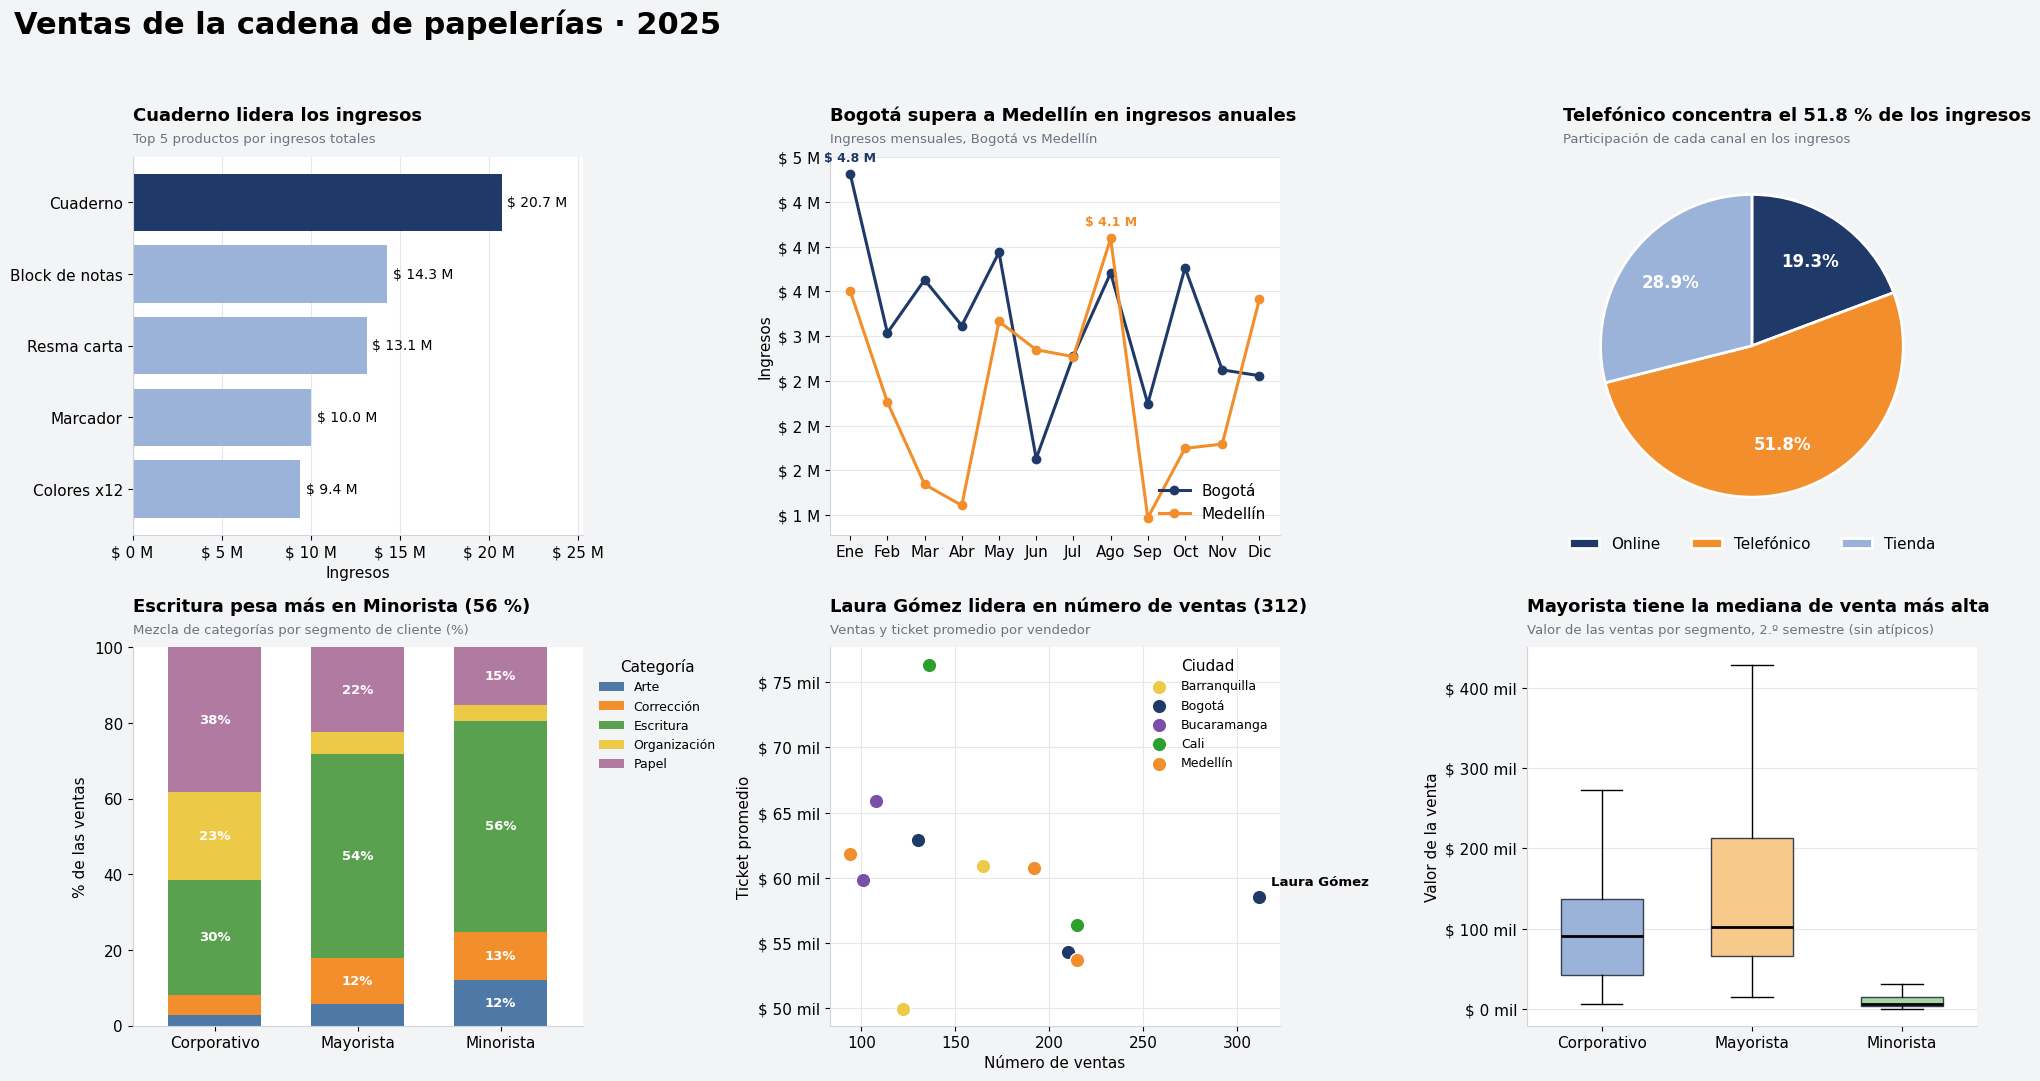

In [52]:
mostrar("v1")

### Ejercicio 9 · Itera: mejora tu prompt
Mira la figura que obtuviste: ¿qué no te gusta? Agrega una sección **AJUSTES** con **al menos dos cambios concretos** (otra paleta, letras más grandes, una dona en lugar del pie, anotar el valor máximo del gráfico de líneas…). Es la **iteración de prompts** que vimos en clase. Repite el ciclo: copia `prompt_v2` a la IA (con tu código base y las reglas), pega el código en `figura_v2.py` y muestra la figura.

In [53]:
prompt_v2 = prompt_v1 + """

AJUSTES (a partir de lo que observé en la versión 1):
1. Lo que observé: el gráfico de pie es difícil de comparar y se ve pesado. Cambio: reemplázalo por una dona, con los porcentajes con un decimal sobre cada sección y, en el centro, el ingreso total de la cadena en millones ("$ 118,7 M") con la palabra "ingresos 2025" debajo.
2. Lo que observé: las letras se ven pequeñas para una pantalla de junta. Cambio: sube el tamaño de letra: títulos de cada gráfico en 15, subtítulos en 11, etiquetas de ejes en 12 y valores sobre las barras en 11.
3. Lo que observé: el gráfico de dispersión no deja ver quién está por encima o por debajo del promedio. Cambio: agrega una línea punteada gris con el promedio de n_ventas y otra con el promedio de ticket_prom, con una etiqueta corta "Promedio".
4. Lo que observé: los paneles se ven apretados y la leyenda del gráfico de barras apiladas queda pegada al siguiente panel. Cambio: deja más espacio entre paneles (figura más grande y mayor separación horizontal y vertical).

Mantén los mismos 6 gráficos, los mismos datos y las mismas reglas técnicas.
"""

print(prompt_v2)


PÚBLICO Y OBJETIVO: La gerente general y la junta directiva verán esta figura proyectada en una sala, para decidir inventario, canales e inversión regional. Debe leerse rápido y a distancia.

PALETA Y TIPOGRAFÍA: Fondo gris muy claro y paneles blancos. Color fijo por ciudad: Bogotá azul oscuro, Medellín naranja, Cali verde, Barranquilla amarillo, Bucaramanga violeta. Fuente sans-serif; títulos en negrita alineados a la izquierda; tamaño mínimo de letra 11.

TÍTULOS: Cada gráfico con un título que diga la conclusión (por ejemplo, "El Cuaderno lidera los ingresos"), calculada con los datos reales, más un subtítulo corto en gris con el nombre de la métrica.

EJES Y NÚMEROS: Valores en pesos como "$ 20 M" (millones) y separador de miles. Etiquetas de ejes claras, sin rotar si es posible.

LIMPIEZA VISUAL: Quita los bordes superior y derecho, cuadrícula horizontal suave, valores escritos sobre las barras, leyendas sin marco.


AJUSTES (a partir de lo que observé en la versión 1):
1. Lo que

In [54]:
%%writefile figura_v2.py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# ---------- Datos (mismas tablas de la figura base) ----------
top_productos = df.groupby("producto")["total"].sum().sort_values(ascending=False).head(5)
bm = df[df["ciudad"].isin(["Bogotá", "Medellín"])]
ing_mes_ciudad = bm.pivot_table(index="mes", columns="ciudad", values="total", aggfunc="sum")
ing_canal = df.groupby("canal")["total"].sum()
tabla_seg_cat = pd.crosstab(df["segmento"], df["categoria"], normalize="index") * 100
vend = (df.groupby(["vendedor", "ciudad"])
          .agg(n_ventas=("id_venta", "count"), ticket_prom=("total", "mean"))
          .reset_index())
sem2 = df[df["mes"] >= 7]

# ---------- Estilo ----------
FONDO = "#F3F4F6"
GRIS = "#6B7280"
COLORES = {"Bogotá": "#1F3A68", "Medellín": "#F28E2B", "Cali": "#2CA02C",
           "Barranquilla": "#EDC948", "Bucaramanga": "#7B4FA8"}
MESES = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]
fmt_M = FuncFormatter(lambda x, _: f"$ {x/1e6:,.0f} M")
fmt_mil = FuncFormatter(lambda x, _: f"$ {x/1e3:,.0f} mil")

plt.rcParams.update({"font.family": "sans-serif", "font.size": 13})

def titulo(ax, texto, sub):
    ax.set_title(texto, loc="left", fontsize=15, fontweight="bold", pad=34)
    ax.text(0, 1.03, sub, transform=ax.transAxes, fontsize=11, color=GRIS, va="bottom")

fig, axs = plt.subplots(2, 3, figsize=(24, 13))
fig.patch.set_facecolor(FONDO)
for ax in axs.flat:
    ax.set_facecolor("white")
    ax.tick_params(labelsize=11)
    for lado in ["top", "right"]:
        ax.spines[lado].set_visible(False)
    for lado in ["left", "bottom"]:
        ax.spines[lado].set_color("#D1D5DB")

# ---------- 1) Top 5 productos ----------
ax = axs[0, 0]
datos = top_productos.sort_values()
colores_b = ["#9CB3D9"] * (len(datos) - 1) + ["#1F3A68"]
barras = ax.barh(datos.index, datos.values, color=colores_b)
ax.bar_label(barras, labels=[f"$ {v/1e6:,.1f} M" for v in datos.values], padding=4, fontsize=11)
ax.set_xlim(0, datos.max() * 1.25)
ax.xaxis.set_major_formatter(fmt_M)
ax.set_xlabel("Ingresos", fontsize=12)
ax.grid(axis="x", color="#E5E7EB"); ax.set_axisbelow(True)
titulo(ax, f"{top_productos.index[0]} lidera los ingresos", "Top 5 productos por ingresos totales")

# ---------- 2) Líneas Bogotá vs Medellín ----------
ax = axs[0, 1]
for c in ing_mes_ciudad.columns:
    s = ing_mes_ciudad[c]
    ax.plot(s.index, s.values, marker="o", linewidth=2.4, color=COLORES.get(c, "#444444"), label=c)
    m = s.idxmax()
    ax.annotate(f"$ {s[m]/1e6:.1f} M", (m, s[m]), textcoords="offset points", xytext=(0, 9),
                ha="center", fontsize=11, color=COLORES.get(c, "#444444"), fontweight="bold")
ax.set_xticks(range(1, 13))
ax.set_xticklabels(MESES)
ax.yaxis.set_major_formatter(fmt_M)
ax.set_ylabel("Ingresos", fontsize=12)
ax.grid(axis="y", color="#E5E7EB"); ax.set_axisbelow(True)
tot = ing_mes_ciudad.sum()
ax.legend(frameon=False, loc="lower right", fontsize=11)
titulo(ax, f"{tot.idxmax()} supera a {tot.idxmin()} en ingresos anuales",
       "Ingresos mensuales, Bogotá vs Medellín")

# ---------- 3) Dona por canal ----------
ax = axs[0, 2]
colores_pie = ["#1F3A68", "#F28E2B", "#9CB3D9"][:len(ing_canal)]
ax.pie(ing_canal.values, labels=None, colors=colores_pie, startangle=90, counterclock=False,
       autopct="%1.1f%%", pctdistance=0.79,
       textprops={"color": "white", "fontsize": 13, "fontweight": "bold"},
       wedgeprops={"width": 0.42, "edgecolor": "white", "linewidth": 2})
ax.text(0, 0.07, f"$ {ing_canal.sum()/1e6:,.1f} M", ha="center", va="center",
        fontsize=20, fontweight="bold", color="#1F2937")
ax.text(0, -0.13, "ingresos 2025", ha="center", va="center", fontsize=12, color=GRIS)
ax.legend(ing_canal.index, loc="lower center", bbox_to_anchor=(0.5, -0.08),
          ncol=len(ing_canal), frameon=False, fontsize=12)
pct_top = ing_canal.max() / ing_canal.sum() * 100
titulo(ax, f"{ing_canal.idxmax()} concentra el {pct_top:.1f} % de los ingresos",
       "Participación de cada canal en los ingresos")
ax.set_ylabel("")

# ---------- 4) Barras apiladas segmento x categoría ----------
ax = axs[1, 0]
paleta = ["#4E79A7", "#F28E2B", "#59A14F", "#EDC948", "#B07AA1"]
tabla_seg_cat.plot.bar(ax=ax, stacked=True, color=paleta[:tabla_seg_cat.shape[1]], width=0.65)
for cont in ax.containers:
    ax.bar_label(cont, labels=[f"{v:.0f}%" if v >= 8 else "" for v in cont.datavalues],
                 label_type="center", color="white", fontsize=11, fontweight="bold")
ax.set_xlabel("")
ax.set_ylabel("% de las ventas", fontsize=12)
ax.set_ylim(0, 100)
ax.tick_params(axis="x", rotation=0, labelsize=12)
ax.legend(frameon=False, title="Categoría", bbox_to_anchor=(1.03, 1), loc="upper left", fontsize=11)
seg, cat = tabla_seg_cat.stack().idxmax()
titulo(ax, f"{cat} pesa más en {seg} ({tabla_seg_cat.loc[seg, cat]:.0f} %)",
       "Mezcla de categorías por segmento de cliente (%)")

# ---------- 5) Dispersión de vendedores ----------
ax = axs[1, 1]
for ciudad, g in vend.groupby("ciudad"):
    ax.scatter(g["n_ventas"], g["ticket_prom"], s=130, color=COLORES.get(ciudad, "#444444"),
               label=ciudad, edgecolor="white", linewidth=1, zorder=3)
prom_x = vend["n_ventas"].mean()
prom_y = vend["ticket_prom"].mean()
ax.axvline(prom_x, color=GRIS, linestyle="--", linewidth=1.3, zorder=1)
ax.axhline(prom_y, color=GRIS, linestyle="--", linewidth=1.3, zorder=1)
ax.text(prom_x, ax.get_ylim()[1], " Promedio", color=GRIS, fontsize=10, va="top")
ax.text(ax.get_xlim()[1], prom_y, "Promedio ", color=GRIS, fontsize=10, ha="right", va="bottom")
mejor = vend.loc[vend["n_ventas"].idxmax()]
ax.annotate(mejor["vendedor"], (mejor["n_ventas"], mejor["ticket_prom"]),
            textcoords="offset points", xytext=(8, 8), fontsize=11, fontweight="bold")
ax.yaxis.set_major_formatter(fmt_mil)
ax.set_xlabel("Número de ventas", fontsize=12)
ax.set_ylabel("Ticket promedio", fontsize=12)
ax.grid(color="#E5E7EB"); ax.set_axisbelow(True)
ax.legend(frameon=False, title="Ciudad", fontsize=10)
titulo(ax, f"{mejor['vendedor']} lidera en número de ventas ({int(mejor['n_ventas'])})",
       "Ventas y ticket promedio por vendedor")

# ---------- 6) Diagrama de cajas ----------
ax = axs[1, 2]
segs = sorted(sem2["segmento"].unique())
datos_box = [sem2.loc[sem2["segmento"] == s, "total"] for s in segs]
bp = ax.boxplot(datos_box, showfliers=False, patch_artist=True, widths=0.55,
                medianprops={"color": "black", "linewidth": 2})
for caja, color in zip(bp["boxes"], ["#9CB3D9", "#F7C98B", "#A9D5A5"]):
    caja.set_facecolor(color)
    caja.set_edgecolor("#374151")
ax.set_xticks(range(1, len(segs) + 1))
ax.set_xticklabels(segs, fontsize=12)
ax.yaxis.set_major_formatter(fmt_mil)
ax.set_ylabel("Valor de la venta", fontsize=12)
ax.grid(axis="y", color="#E5E7EB"); ax.set_axisbelow(True)
med = sem2.groupby("segmento")["total"].median()
titulo(ax, f"{med.idxmax()} tiene la mediana de venta más alta",
       "Valor de las ventas por segmento, 2.º semestre (sin atípicos)")

# ---------- Título general y espaciado ----------
fig.suptitle("Ventas de la cadena de papelerías · 2025", x=0.01, ha="left",
             fontsize=24, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.95])
fig.subplots_adjust(hspace=0.55, wspace=0.42)

Overwriting figura_v2.py


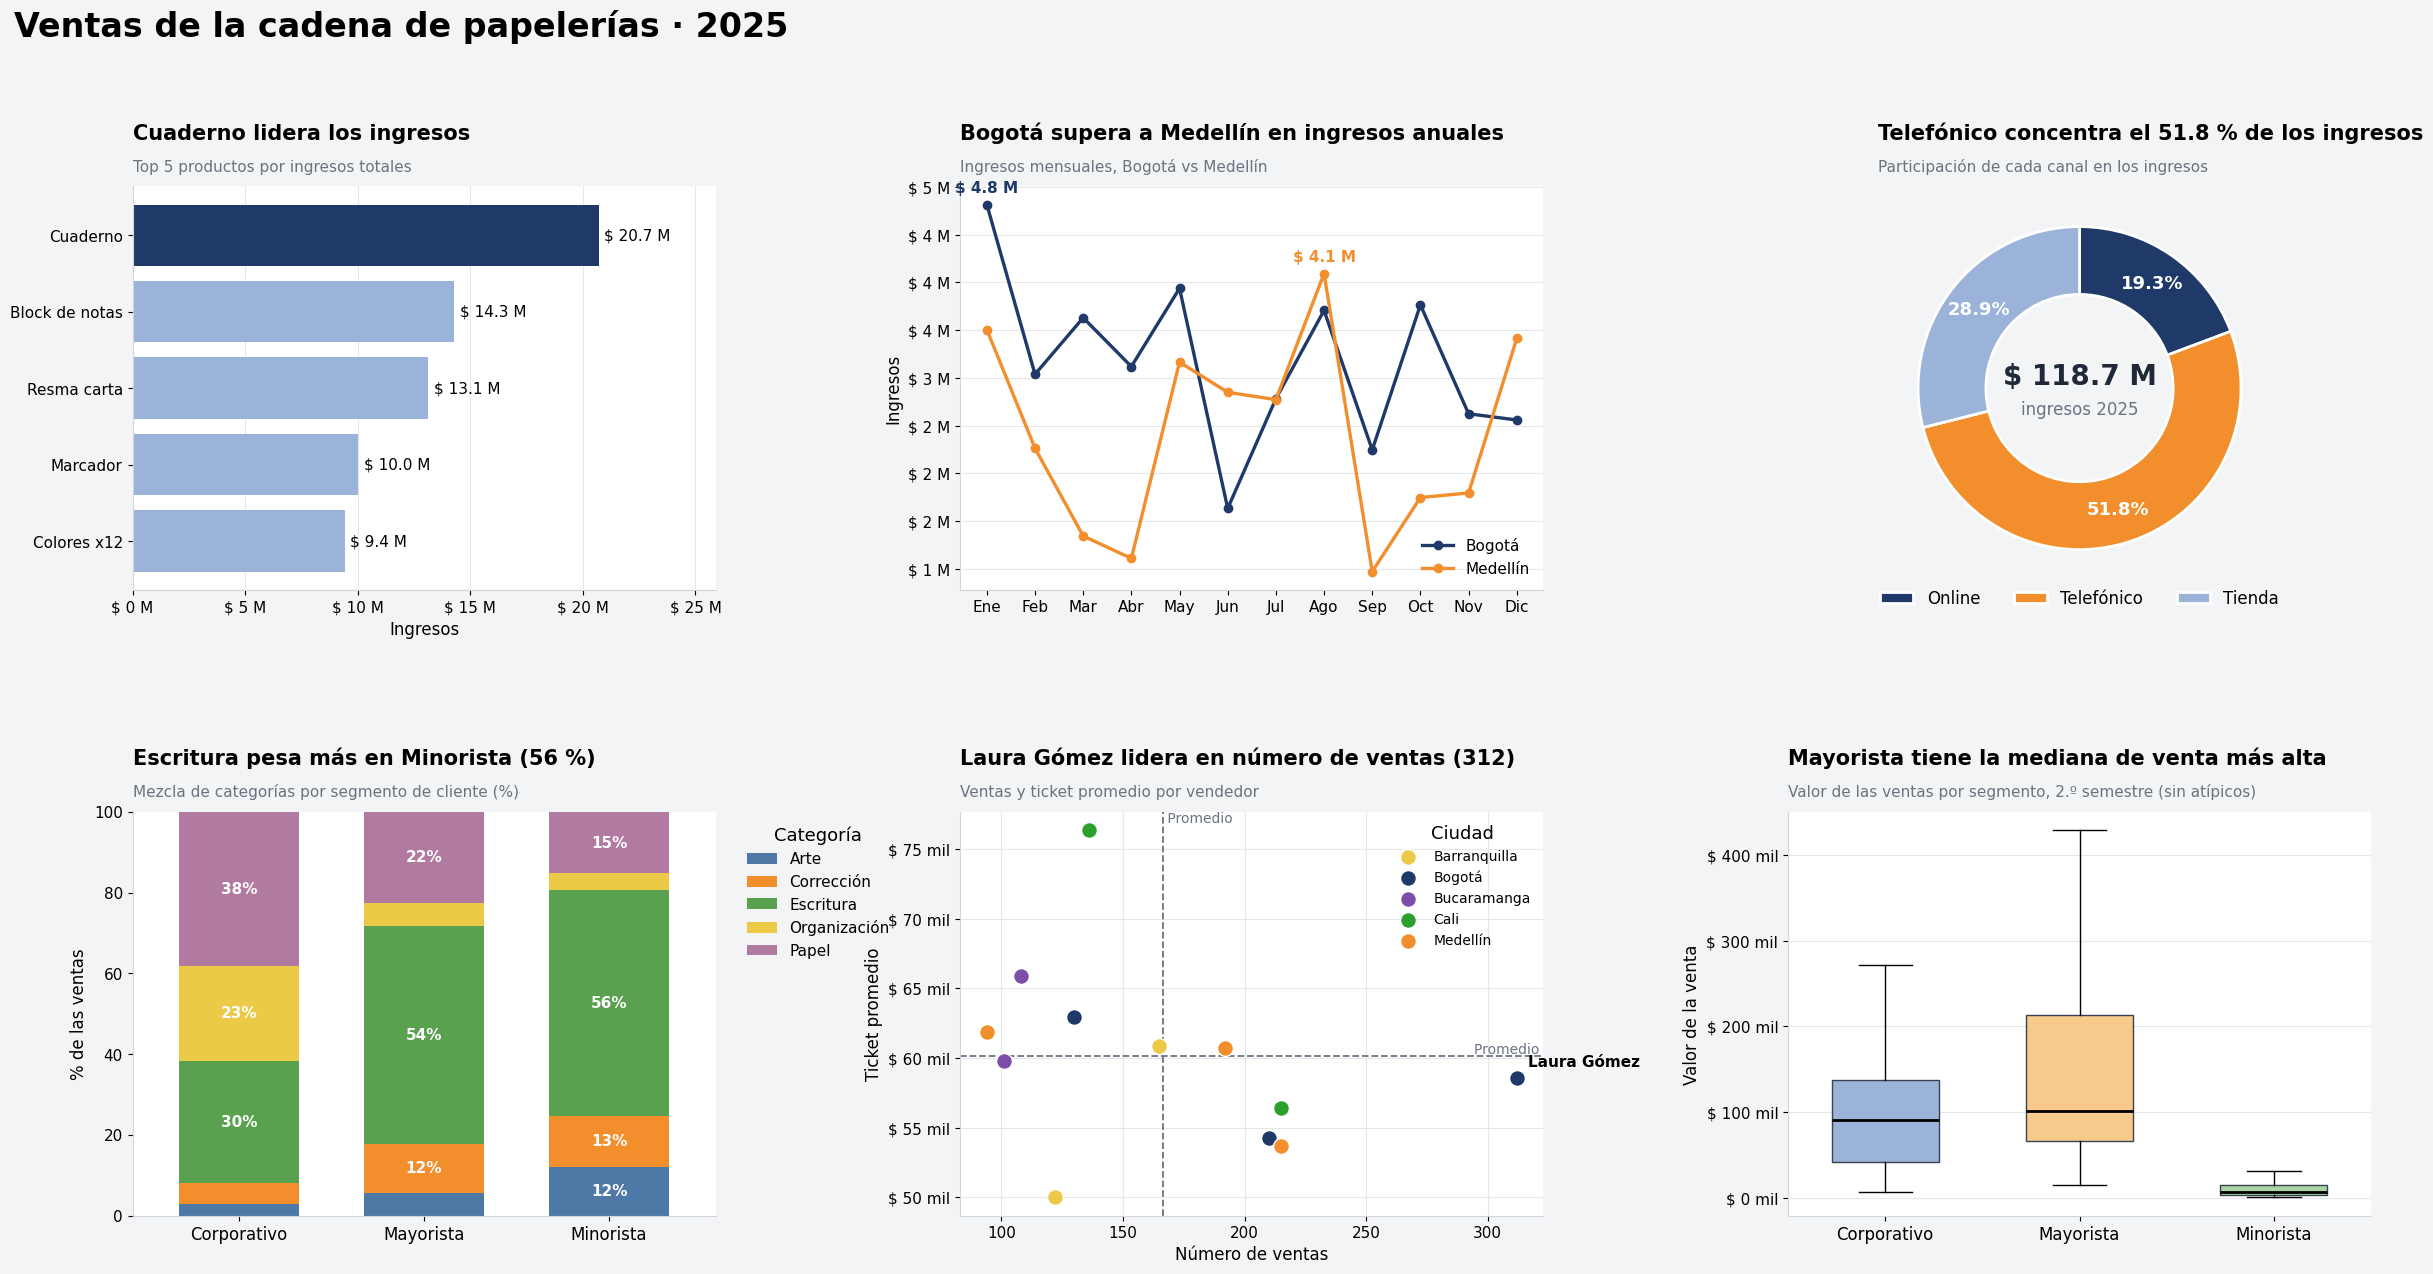

In [55]:
mostrar("v2")

### Ejercicio 10 *(opcional)* · Una tercera versión
Si quieres seguir mejorando, crea `prompt_v3` (parte de `prompt_v2`), repite el ciclo con `figura_v3.py` y muestra `mostrar("v3")`.

In [56]:
# prompt_v3 = prompt_v2 + """
#
# AJUSTES FINALES: ...
# """
# print(prompt_v3)

In [57]:
# ✅ Verificación
import os
assert os.path.exists("figura_v1.py") and os.path.exists("figura_v2.py"), "Faltan figura_v1.py y figura_v2.py: pega el código de cada versión"
assert "ESCRIBE AQUÍ" not in prompt_v1 and prompt_v2 != prompt_v1 and "ESCRIBE AQUÍ" not in prompt_v2, "Completa tus prompts v1 y v2"
print("Parte C correcta ✔")

Parte C correcta ✔


---
# Parte D · Elige tu favorita y publícala
### Ejercicio 11 · Tu dashboard final y tus conclusiones
Mira tus versiones y **elige la que más te guste**. Luego escribe **3 hallazgos**: frases cortas con **cifras reales** sacadas de tus tablas. Se mostrarán debajo de tu dashboard.

*Ejemplo de hallazgo:* "Bogotá genera el 32 % de los ingresos de la cadena."

In [58]:
figura_elegida = "v2"      # cambia por "v1", "v2" o "v3"

total_cadena = df["total"].sum()

# Hallazgo 1: ciudad con más ingresos
ing_ciudad = df.groupby("ciudad")["total"].sum()
ciudad_top = ing_ciudad.idxmax()
pct_ciudad = ing_ciudad.max() / total_cadena * 100

# Hallazgo 2: canal con más ingresos
canal_top = ing_canal.idxmax()
pct_canal = ing_canal.max() / ing_canal.sum() * 100

# Hallazgo 3: producto líder
prod_top = top_productos.index[0]
pct_prod = top_productos.iloc[0] / total_cadena * 100

hallazgos = [
    f"{ciudad_top} genera el {pct_ciudad:.1f} % de los ingresos de la cadena (${ing_ciudad.max()/1e6:,.1f} M de ${total_cadena/1e6:,.1f} M).",
    f"El canal {canal_top} concentra el {pct_canal:.1f} % de los ingresos, más que los otros canales juntos." if pct_canal > 50
    else f"El canal {canal_top} es el que más vende, con el {pct_canal:.1f} % de los ingresos.",
    f"{prod_top} es el producto estrella: ${top_productos.iloc[0]/1e6:,.1f} M, el {pct_prod:.1f} % de los ingresos de la cadena.",
]

for h in hallazgos:
    print("•", h)

• Bogotá genera el 31.9 % de los ingresos de la cadena ($37.8 M de $118.7 M).
• El canal Telefónico concentra el 51.8 % de los ingresos, más que los otros canales juntos.
• Cuaderno es el producto estrella: $20.7 M, el 17.5 % de los ingresos de la cadena.


In [59]:
# ✅ Verificación
import os
assert os.path.exists(f"figura_{figura_elegida}.py"), f"No existe figura_{figura_elegida}.py: revisa figura_elegida"
assert len(hallazgos) == 3 and all(len(h) > 25 and "ESCRIBE AQUÍ" not in h for h in hallazgos), "Escribe tus 3 hallazgos con cifras"
print("Ejercicio 11 correcto ✔")

Ejercicio 11 correcto ✔


### Tu dashboard final
Ejecuta la celda: muestra la versión que elegiste y tus tres hallazgos. **Esta es la salida que se verá en GitHub.**

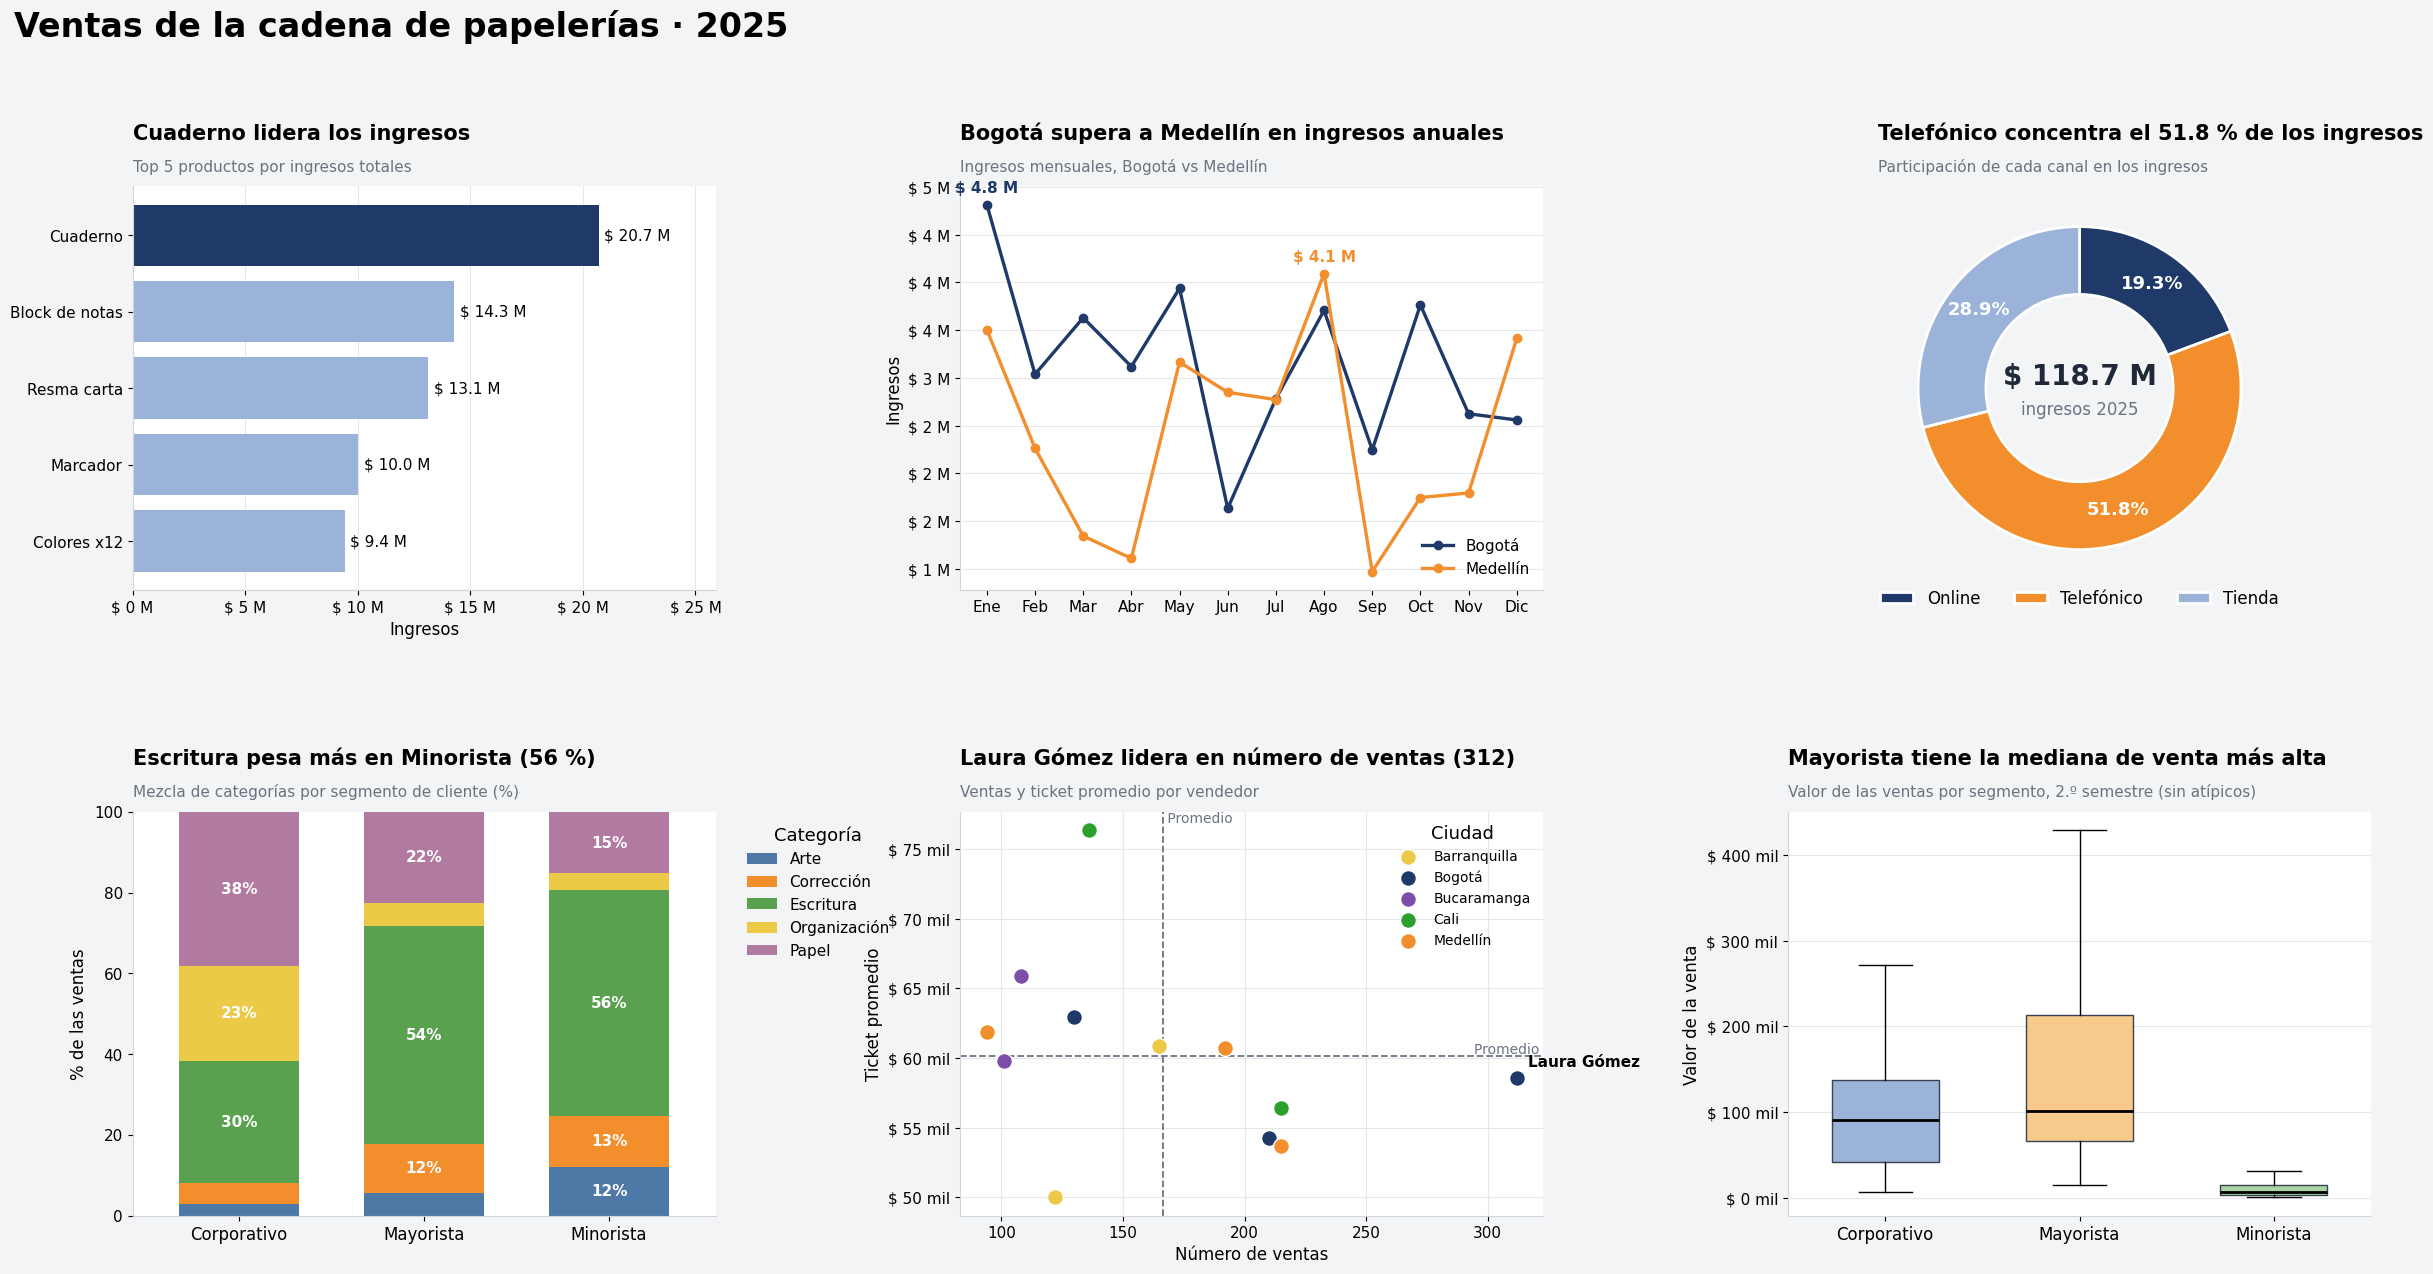

Hallazgos:
• Bogotá genera el 31.9 % de los ingresos de la cadena ($37.8 M de $118.7 M).
• El canal Telefónico concentra el 51.8 % de los ingresos, más que los otros canales juntos.
• Cuaderno es el producto estrella: $20.7 M, el 17.5 % de los ingresos de la cadena.


In [60]:
mostrar(figura_elegida)

print("Hallazgos:")
for h in hallazgos:
    print("•", h)

### Ejercicio 12 · Publica tu notebook en GitHub
GitHub muestra los notebooks **con sus figuras**, así que tu notebook publicado es tu dashboard. Solo necesitas una cuenta gratuita en [github.com](https://github.com).

**Antes de publicar:**
- Ejecuta todo el notebook de arriba abajo (*Entorno de ejecución → Ejecutar todo*) para que las figuras queden guardadas en las salidas.
- **Nunca escribas tu API key dentro de una celda.** Los *Secrets* de Colab no se guardan en el notebook y por eso son seguros; el repositorio será público.

**Pasos:**
1. **Crea el repositorio:** botón **New** → nombre `mi-dashboard-ventas` → **Public** → *Create repository*.
2. **Guarda el notebook en GitHub.** Opción A: en Colab, *Archivo → Guardar una copia en GitHub*, autoriza, elige tu repositorio y acepta. Opción B: *Archivo → Descargar → .ipynb* y, en el repositorio, **Add file → Upload files** y arrastra el archivo.
3. **Abre el notebook en el repositorio** (haz clic en el archivo `.ipynb`): GitHub lo dibuja con tus figuras.
4. **Copia el enlace** de la barra del navegador. Debe verse así: `https://github.com/TU-USUARIO/mi-dashboard-ventas/blob/main/NOMBRE.ipynb`
5. **Compruébalo:** ábrelo en una ventana de incógnito. Si lo ves sin iniciar sesión, está público.

**Si no se ven las figuras:** vuelve a Colab, ejecuta todo y guarda de nuevo. Si GitHub dice *Unable to render code block*, recarga la página unos segundos después.

---
**Para entregar:** (1) el **enlace público** de tu notebook en GitHub, con tu dashboard final visible, todos los integrantes deben estar como colaboradores en el repositorio, y (2) tus prompts (`prompt_v1`, `prompt_v2` y, si la hiciste, `prompt_v3`) más **tres líneas** sobre qué tuviste que corregir de lo que hizo Gemini y cómo lo pediste (escríbelas en una celda de texto al final del notebook) (3) El notebook (ipynb) con los nombres de todos los integrantes.